In [ ]:
!pip install pycaret
!pip install markupsafe==2.0.1
!pip jinja2

     |████████████████████████████████| 320 kB 5.0 MB/s            
     |████████████████████████████████| 24.2 MB 30.0 MB/s            
     |████████████████████████████████| 122 kB 43.3 MB/s            
  Preparing metadata (setup.py) ... - done
     |████████████████████████████████| 17.8 MB 2.5 MB/s            
     |████████████████████████████████| 636 kB 49.3 MB/s            
     |████████████████████████████████| 10.4 MB 634 kB/s            
     |████████████████████████████████| 167 kB 71.6 MB/s            
     |████████████████████████████████| 25.9 MB 50.1 MB/s            
     |████████████████████████████████| 6.8 MB 19.2 MB/s            
     |████████████████████████████████| 1.0 MB 37.9 MB/s            
     |████████████████████████████████| 184 kB 44.4 MB/s            
     |████████████████████████████████| 271 kB 18.3 MB/s            
     |████████████████████████████████| 14.8 MB 55.5 MB/s            
     |████████████████████████████████| 81 kB 6.7 MB/s  

In [ ]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import pycaret
import warnings
import jinja2

from sklearn.preprocessing import LabelEncoder
from scipy import stats
from scipy.stats import *
from pycaret.regression import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

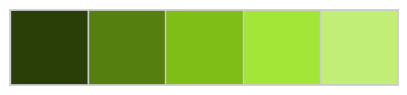

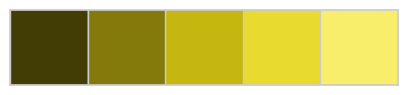

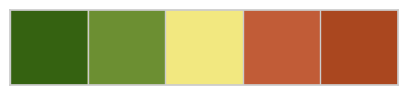

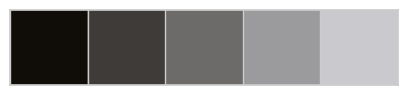

In [ ]:

olive_grad = ['#2A3F07', '#557F0F', '#7FBE17', '#A4E637', '#C1EE76']
yellow_grad = ['#413D05', '#837A0B', '#C5B710', '#E8DA2E', '#F9EE6A']
color_mix = ['#356211', '#6C8F32', '#F2E880', '#C15C37', '#AA471F']
black_grad = ['#100C07', '#3E3B39', '#6D6A6A', '#9B9A9C', '#CAC9CD']


sns.palplot(olive_grad)
sns.palplot(yellow_grad)
sns.palplot(color_mix)
sns.palplot(black_grad)

In [ ]:
ds = pd.read_csv('../input/avocado-prices/avocado.csv')
ds.head().style.background_gradient(cmap='Greens').set_properties(**{'font-family': 'Segoe UI'}).hide_index()

Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-12-27,1.330000,64236.620000,1036.740000,54454.850000,48.160000,8696.870000,8603.620000,93.250000,0.000000,conventional,2015,Albany
1,2015-12-20,1.350000,54876.980000,674.280000,44638.810000,58.330000,9505.560000,9408.070000,97.490000,0.000000,conventional,2015,Albany
2,2015-12-13,0.930000,118220.220000,794.700000,109149.670000,130.500000,8145.350000,8042.210000,103.140000,0.000000,conventional,2015,Albany
3,2015-12-06,1.080000,78992.150000,1132.000000,71976.410000,72.580000,5811.160000,5677.400000,133.760000,0.000000,conventional,2015,Albany
4,2015-11-29,1.280000,51039.600000,941.480000,43838.390000,75.780000,6183.950000,5986.260000,197.690000,0.000000,conventional,2015,Albany


In [ ]:
print('\033[92m\033[1m'+'.: Imported Dataset Info :.'+'\033[0m')
print('\033[92m*' * 30+'\033[0m')
print('Total Rows:'+'\033[92m\033[1m', ds.shape[0])
print('\033[0m'+'Total Columns:'+'\033[92m\033[1m', ds.shape[1])
print('\033[0m\033[92m'+'*' * 30+'\033[0m')
print('\n')

print('\033[92m\033[1m'+'.: Dataset Details :.'+'\033[0m')
print('\033[0m\033[92m'+'*' * 30+'\033[0m')
ds.info(memory_usage = False)

.: Imported Dataset Info :.
******************************
Total Rows: 18249
Total Columns: 14
******************************


.: Dataset Details :.
******************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  object 
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  object 
 12  year          18249 non-null  int64  
 13  region        18249 non-null  object 
dtypes: float64(9), in

****************************************
.: Total Avocado based on each Type :.
****************************************


conventional    9126
organic         9123
Name: type, dtype: int64

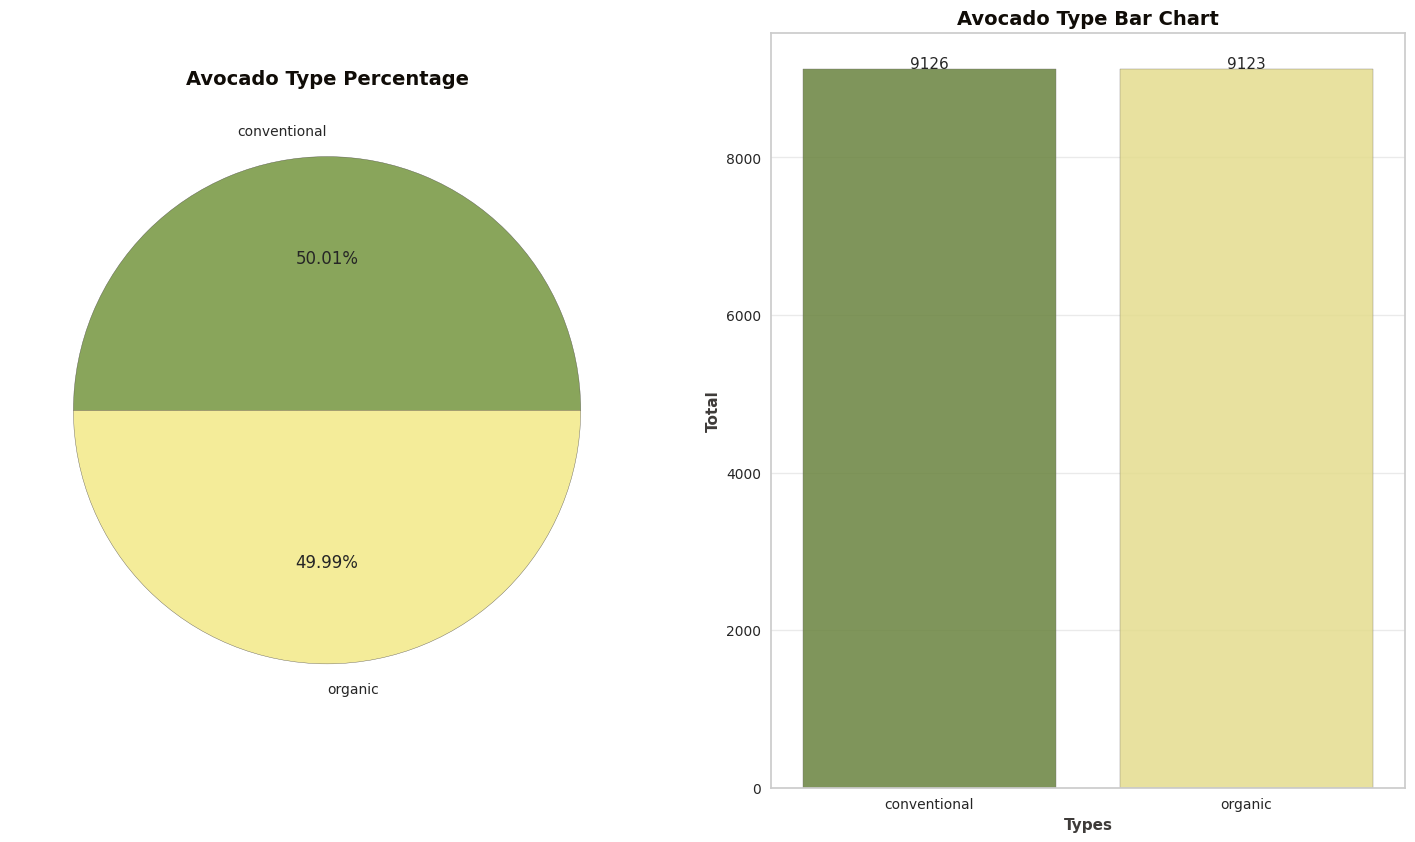

In [ ]:

colors = color_mix[1:3]
labels = ds['type'].dropna().unique()
order = ds['type'].value_counts().index


plt.figure(figsize=(18, 10))


plt.subplot(1, 2, 1)
plt.title('Avocado Type Percentage', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif',
          color = black_grad[0])
plt.pie(ds['type'].value_counts(), labels = order, colors = colors,
        wedgeprops = dict(alpha = 0.8, edgecolor = black_grad[1]), autopct = '%.2f%%')

countplt = plt.subplot(1, 2, 2)
plt.title('Avocado Type Bar Chart', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
ax = sns.countplot(x = 'type', data = ds, palette = colors, order = order, edgecolor = black_grad[2], alpha = 0.85)
for rect in ax.patches:
    ax.text (rect.get_x()+rect.get_width()/2, rect.get_height()+0.75,rect.get_height(), horizontalalignment = 'center',
             fontsize = 11)

plt.xlabel('Types', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Total', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
countplt

print('\033[92m'+'*' * 40)
print('\033[92m\033[1m'+'.: Total Avocado based on each Type :.'+'\033[0m')
print('\033[92m'+'*' * 40+'\033[0m')
ds.type.value_counts(dropna=False)

***********************************
.: Total Avocado based on Year :.
***********************************


2017    5722
2016    5616
2015    5615
2018    1296
Name: year, dtype: int64

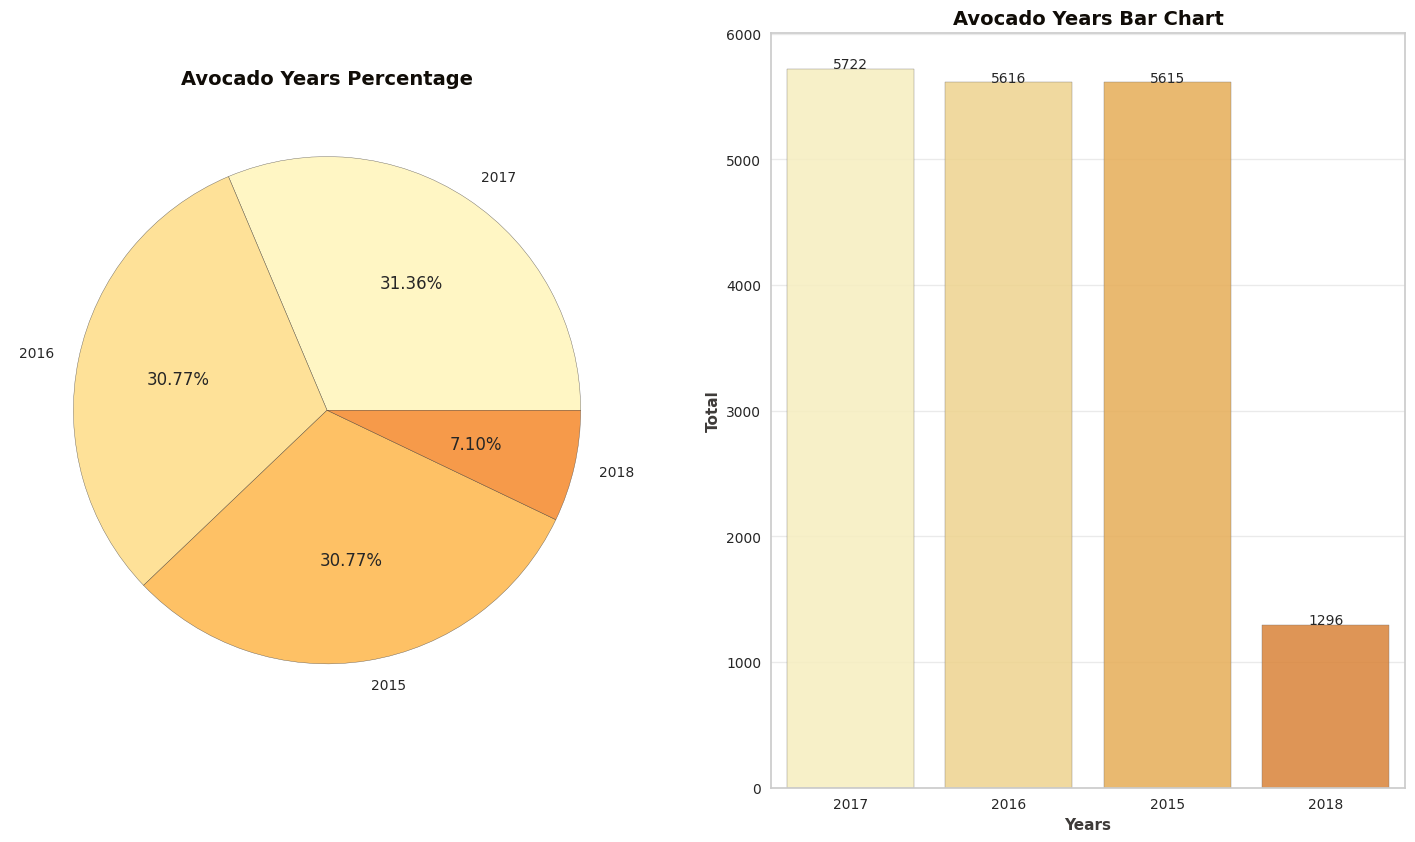

In [ ]:
colors = sns.color_palette('YlOrBr')
labels = ds['year'].dropna().unique()
order = ds['year'].value_counts().index

plt.figure(figsize=(18,10))


plt.subplot(1,2,1)
plt.title('Avocado Years Percentage', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
plt.pie(ds['year'].value_counts(), labels = order, colors = colors,
        wedgeprops = dict(alpha = 0.8, edgecolor = black_grad[1]), autopct = '%.2f%%')


countplt = plt.subplot(1,2,2)
plt.title('Avocado Years Bar Chart', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
ax = sns.countplot(x = 'year', data = ds, palette = colors, order = order, edgecolor = black_grad[2], alpha = 0.85)
for rect in ax.patches:
    ax.text (rect.get_x()+rect.get_width()/2, rect.get_height()+0.75,rect.get_height(), horizontalalignment = 'center',
             fontsize = 10)

plt.xlabel('Years', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Total', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
countplt


print('\033[92m'+'*' * 35)
print('\033[92m\033[1m'+'.: Total Avocado based on Year :.'+'\033[0m')
print('\033[92m'+'*' * 35+'\033[0m')
ds.year.value_counts(dropna=False)

In [ ]:
print('\033[92m'+'*' * 38)
print('\033[92m\033[1m'+'.: Total Avocado based on Regions :.'+'\033[0m')
print('\033[92m'+'*' * 38)
ds.region.value_counts(dropna=False)

**************************************
.: Total Avocado based on Regions :.
**************************************


Albany                 338
Sacramento             338
Northeast              338
NorthernNewEngland     338
Orlando                338
Philadelphia           338
PhoenixTucson          338
Pittsburgh             338
Plains                 338
Portland               338
RaleighGreensboro      338
RichmondNorfolk        338
Roanoke                338
SanDiego               338
Atlanta                338
SanFrancisco           338
Seattle                338
SouthCarolina          338
SouthCentral           338
Southeast              338
Spokane                338
StLouis                338
Syracuse               338
Tampa                  338
TotalUS                338
West                   338
NewYork                338
NewOrleansMobile       338
Nashville              338
Midsouth               338
BaltimoreWashington    338
Boise                  338
Boston                 338
BuffaloRochester       338
California             338
Charlotte              338
Chicago                338
C

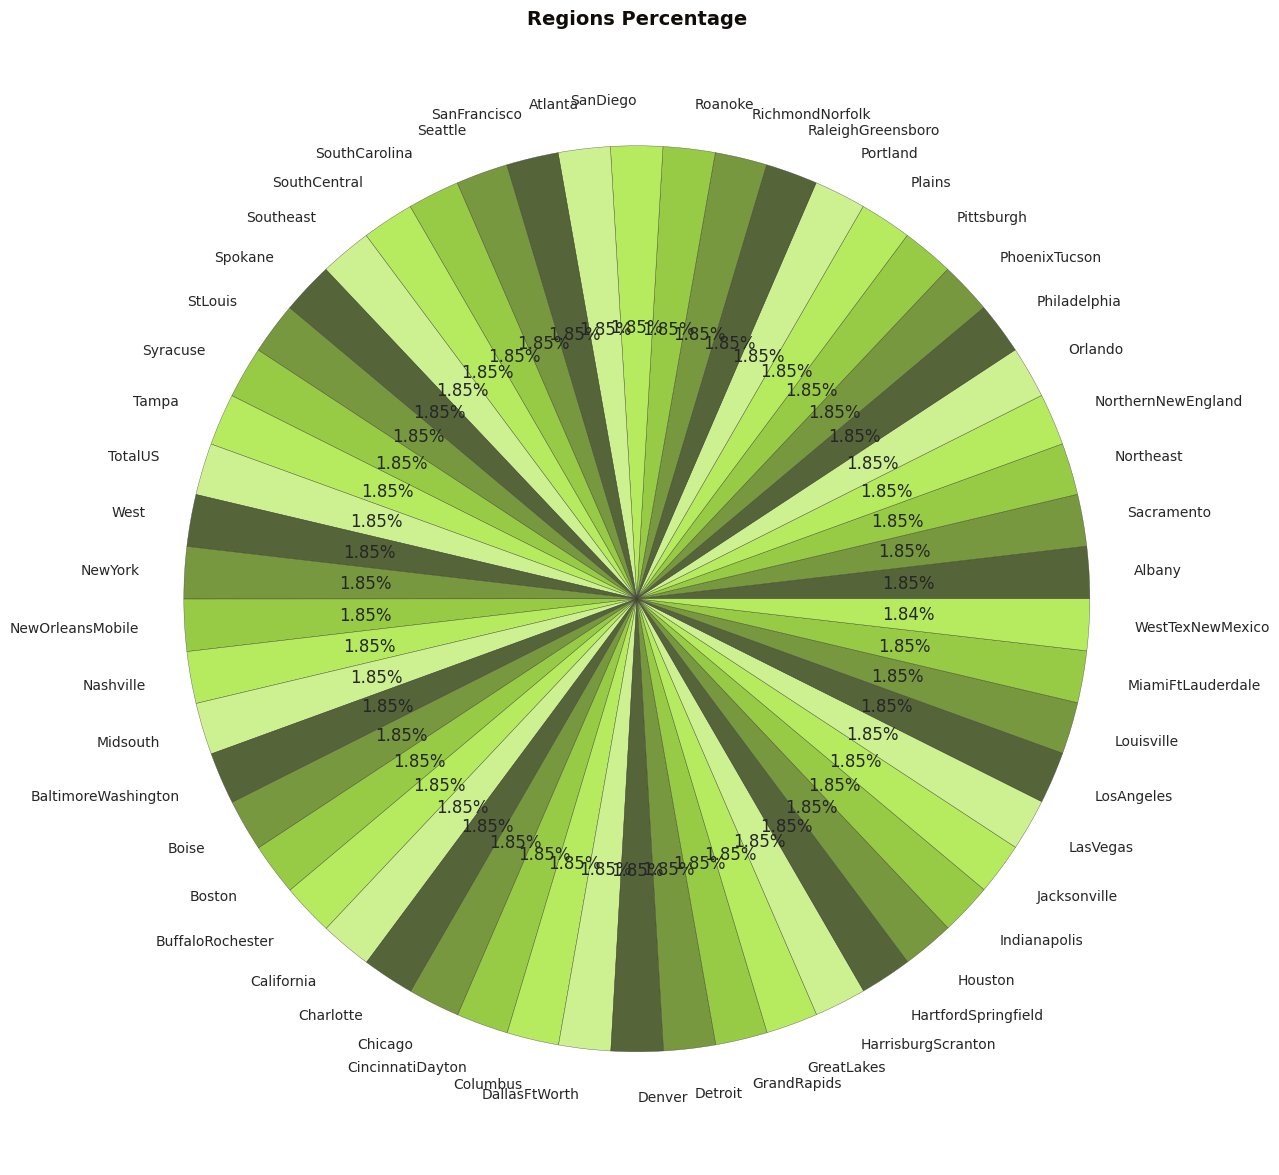

In [ ]:
colors = olive_grad[0:5]
labels = ds['region'].dropna().unique()
order = ds['region'].value_counts().index

plt.figure(figsize = (15, 15))
plt.title('Regions Percentage', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
plt.pie(ds['region'].value_counts(), labels = order, colors = colors,
        wedgeprops = dict(alpha = 0.8, edgecolor = black_grad[1]), autopct = '%.2f%%');

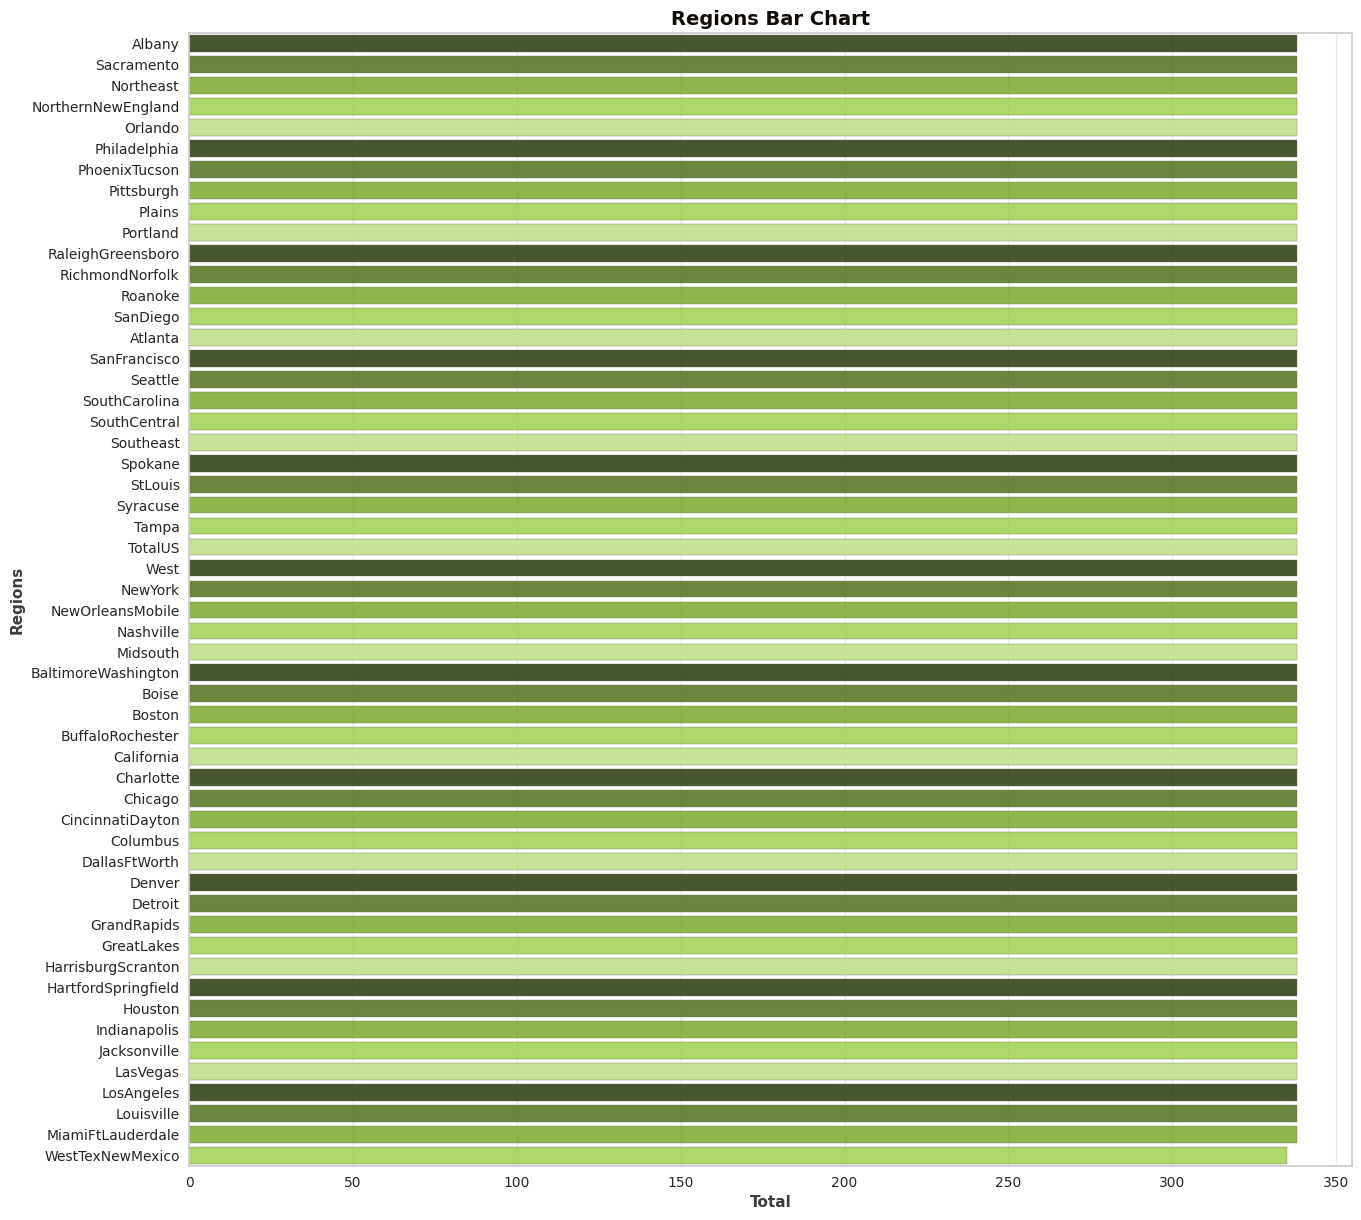

In [ ]:
plt.figure(figsize = (15, 15))
plt.title('Regions Bar Chart', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
sns.countplot(y = 'region', data = ds, order = order, palette = colors, edgecolor = black_grad[2], alpha = 0.85)
plt.xlabel('Total', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Regions', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'x', alpha = 0.4);

In [ ]:

ds[['AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags',
    'XLarge Bags']].describe().T.style.background_gradient(cmap='YlOrBr').set_properties(**{'font-family': 'Segoe UI'})

,count,mean,std,min,25%,50%,75%,max
AveragePrice,18249.000000,1.405978,0.402677,0.440000,1.100000,1.370000,1.660000,3.250000
Total Volume,18249.000000,850644.013009,3453545.355399,84.560000,10838.580000,107376.760000,432962.290000,62505646.520000
4046,18249.000000,293008.424531,1264989.081763,0.000000,854.070000,8645.300000,111020.200000,22743616.170000
4225,18249.000000,295154.568356,1204120.401135,0.000000,3008.780000,29061.020000,150206.860000,20470572.610000
4770,18249.000000,22839.735993,107464.068435,0.000000,0.000000,184.990000,6243.420000,2546439.110000
Total Bags,18249.000000,239639.202060,986242.399216,0.000000,5088.640000,39743.830000,110783.370000,19373134.370000
Small Bags,18249.000000,182194.686696,746178.514962,0.000000,2849.420000,26362.820000,83337.670000,13384586.800000
Large Bags,18249.000000,54338.088145,243965.964547,0.000000,127.470000,2647.710000,22029.250000,5719096.610000
XLarge Bags,18249.000000,3106.426507,17692.894652,0.000000,0.000000,0.000000,132.500000,551693.650000


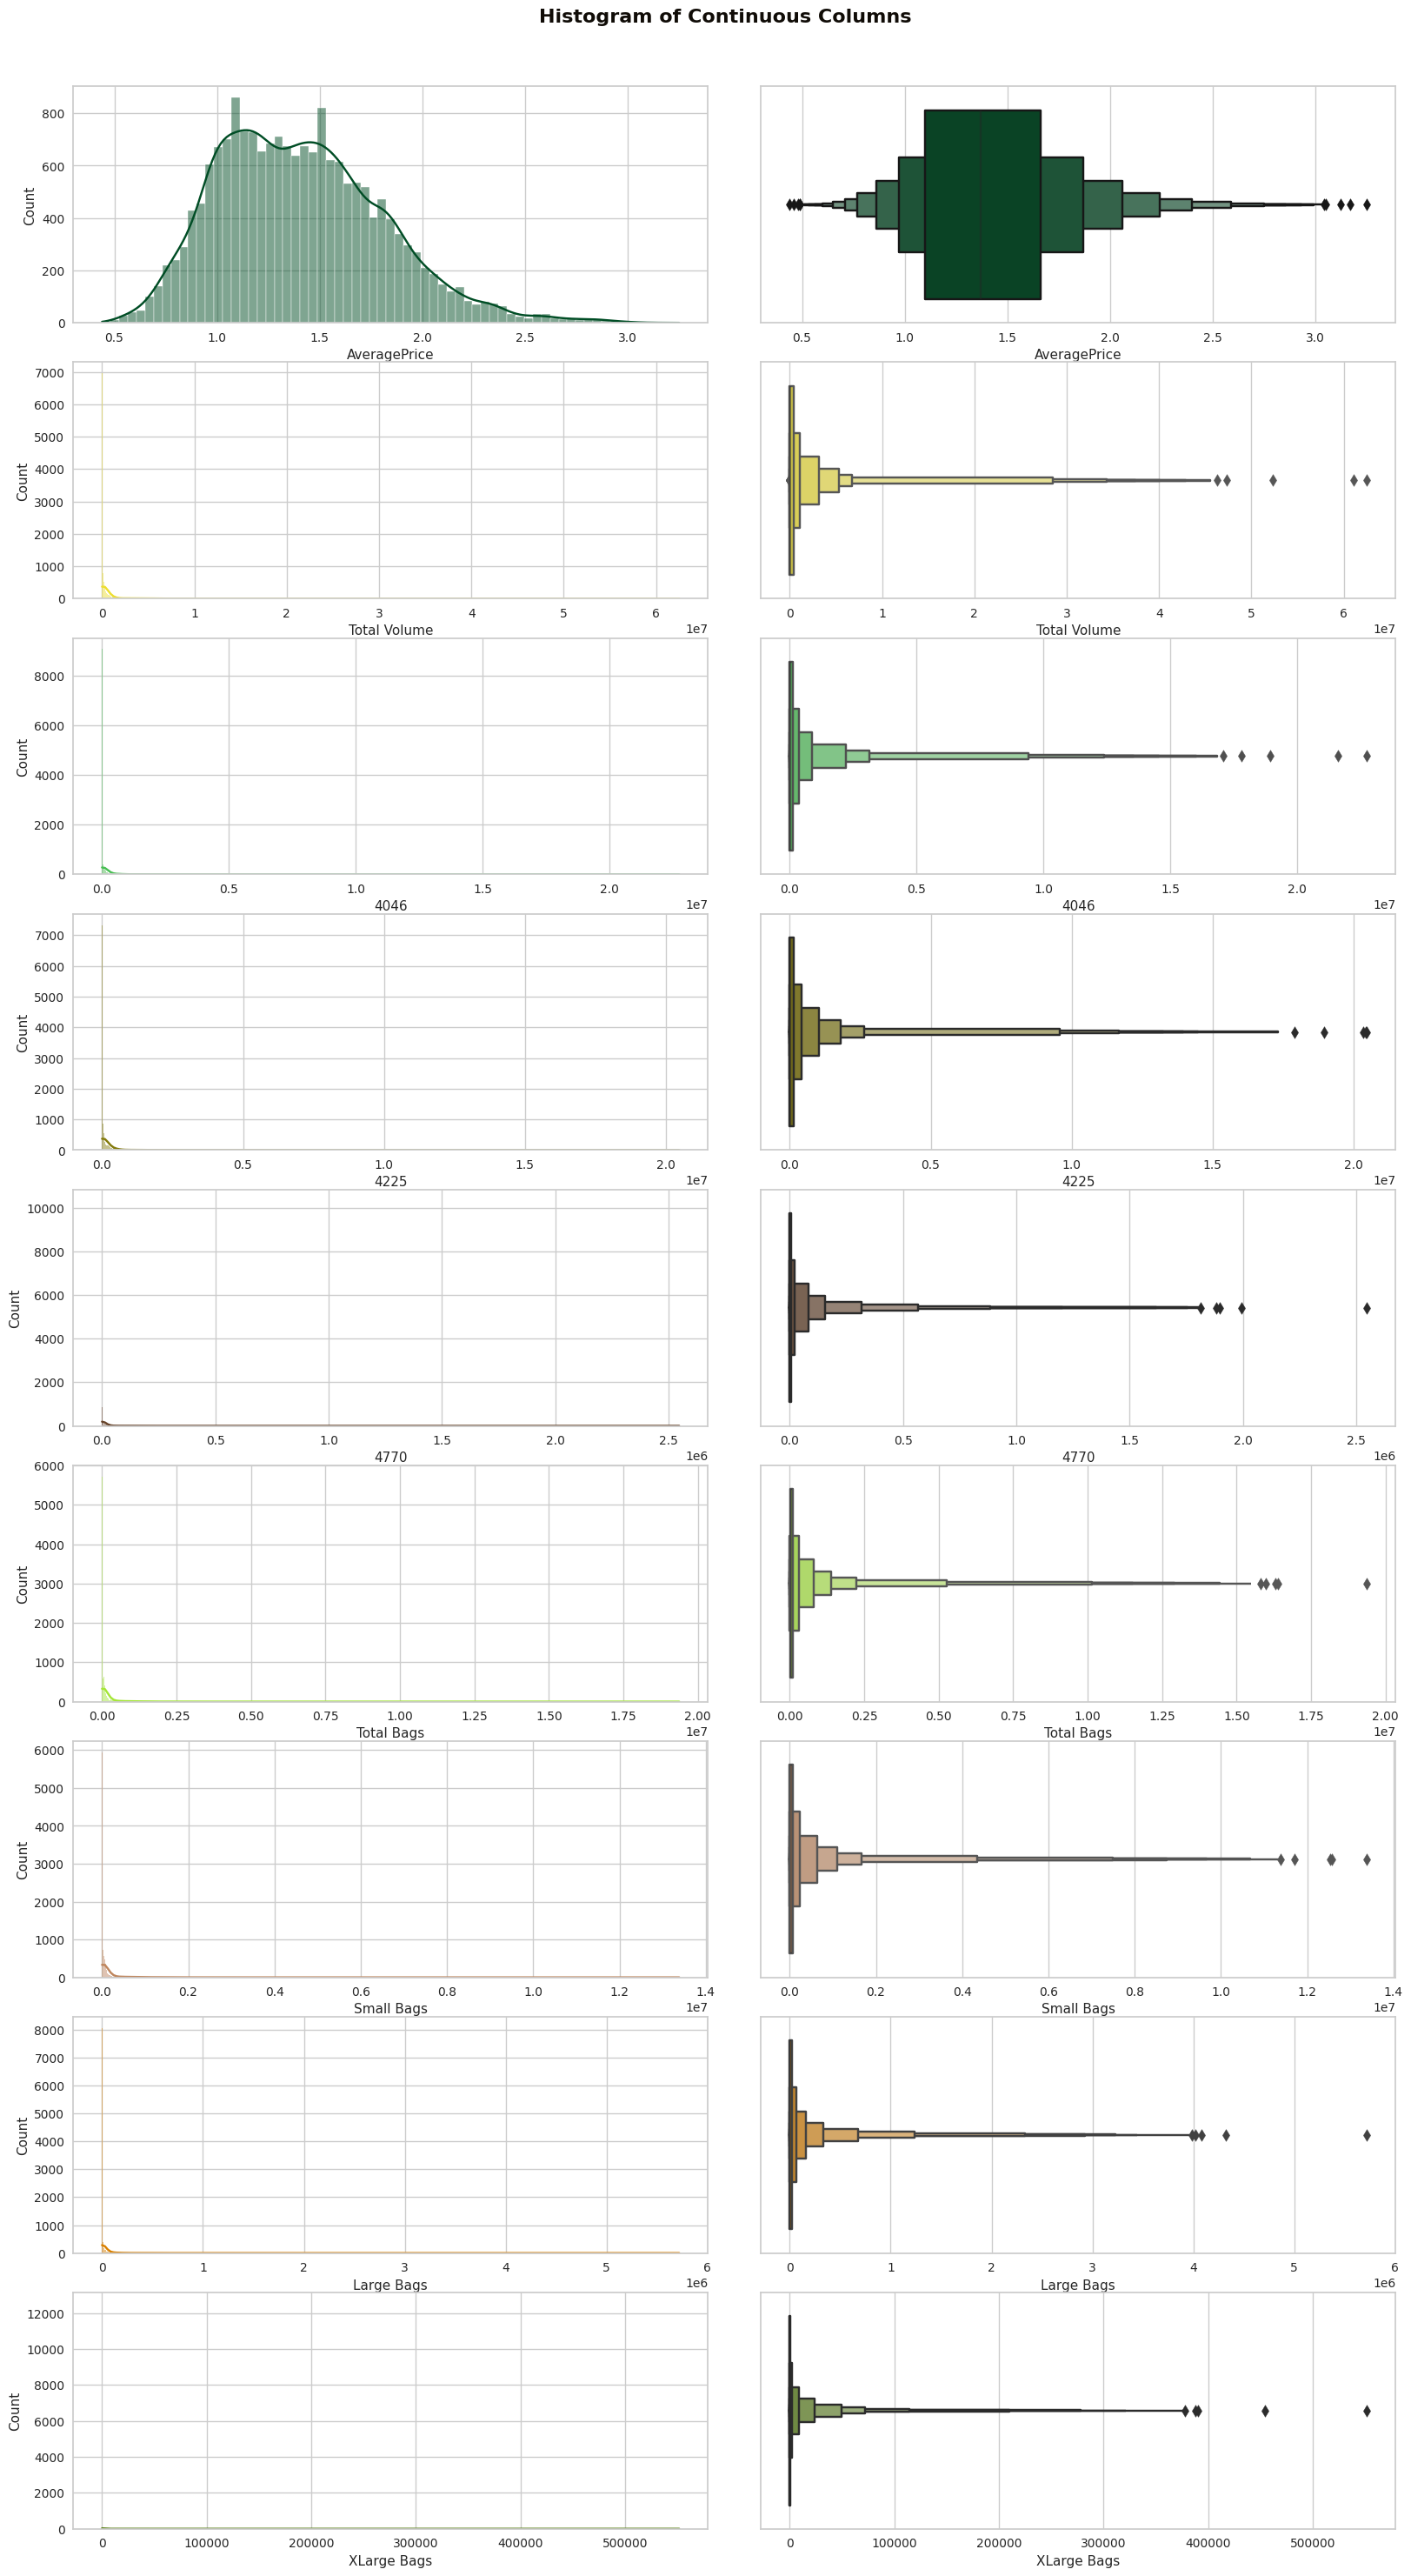

In [ ]:
fig, axs = plt.subplots(9, 2, figsize = (16, 30))

fig.tight_layout()
fig.subplots_adjust(top = 0.95)
fig.suptitle('Histogram of Continuous Columns', fontweight = 'bold', fontsize = 16, fontfamily = 'sans-serif',
             color = black_grad[0])

sns.histplot(data = ds, x = 'AveragePrice', kde = True, ax = axs[0, 0], color = '#004D25')
sns.boxenplot(data = ds, x = 'AveragePrice', ax = axs[0, 1], color = '#004D25')

sns.histplot(data = ds, x = 'Total Volume', kde = True, ax = axs[1, 0], color = '#EDDE30')
sns.boxenplot(data = ds, x = 'Total Volume', ax = axs[1, 1], color = '#EDDE30')

sns.histplot(data = ds, x='4046', kde = True, ax = axs[2, 0], color = '#48BF53')
sns.boxenplot(data = ds, x = '4046', ax = axs[2, 1], color = '#48BF53')

sns.histplot(data = ds, x = '4225', kde = True, ax = axs[3, 0], color = '#837A0B')
sns.boxenplot(data = ds, x = '4225', ax = axs[3, 1], color = '#837A0B')

sns.histplot(data = ds, x = '4770', kde = True, ax = axs[4, 0], color = '#664228')
sns.boxenplot(data = ds, x = '4770', ax = axs[4, 1], color = '#664228')

sns.histplot(data = ds, x = 'Total Bags', kde = True, ax = axs[5, 0], color = '#A4E637')
sns.boxenplot(data = ds, x = 'Total Bags', ax = axs[5, 1], color = '#A4E637')

sns.histplot(data = ds, x = 'Small Bags', kde = True, ax = axs[6, 0], color = '#BF865D')
sns.boxenplot(data = ds, x = 'Small Bags', ax = axs[6, 1], color = '#BF865D')


sns.histplot(data = ds, x = 'Large Bags', kde = True, ax = axs[7, 0], color = '#D98000')
sns.boxenplot(data = ds, x = 'Large Bags', ax = axs[7, 1], color = '#D98000')

sns.histplot(data = ds, x = 'XLarge Bags', kde = True, ax = axs[8, 0], color = '#557F0F')
sns.boxenplot(data = ds, x = 'XLarge Bags', ax = axs[8, 1], color = '#557F0F');

In [ ]:
print('\033[92m\033[1m'+'.: Continuous Columns Skewness :.'+'\033[0m')
print('\033[92m*' * 34+'\033[0m')
ds[['AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags',
    'XLarge Bags']].skew(axis = 0, skipna = True)

.: Continuous Columns Skewness :.
**********************************


AveragePrice     0.580303
Total Volume     9.007687
4046             8.648220
4225             8.942466
4770            10.159396
Total Bags       9.756072
Small Bags       9.540660
Large Bags       9.796455
XLarge Bags     13.139751
dtype: float64

In [ ]:
print('\033[92m\033[1m'+'.: Continuous Columns Kurtosis :.'+'\033[0m')
print('\033[92m*' * 34+'\033[0m')
ds[['AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags',
    'XLarge Bags']].kurt(axis = 0, skipna = True)

.: Continuous Columns Kurtosis :.
**********************************


AveragePrice      0.325196
Total Volume     92.104458
4046             86.809113
4225             91.949022
4770            132.563441
Total Bags      112.272156
Small Bags      107.012885
Large Bags      117.999481
XLarge Bags     233.602612
dtype: float64

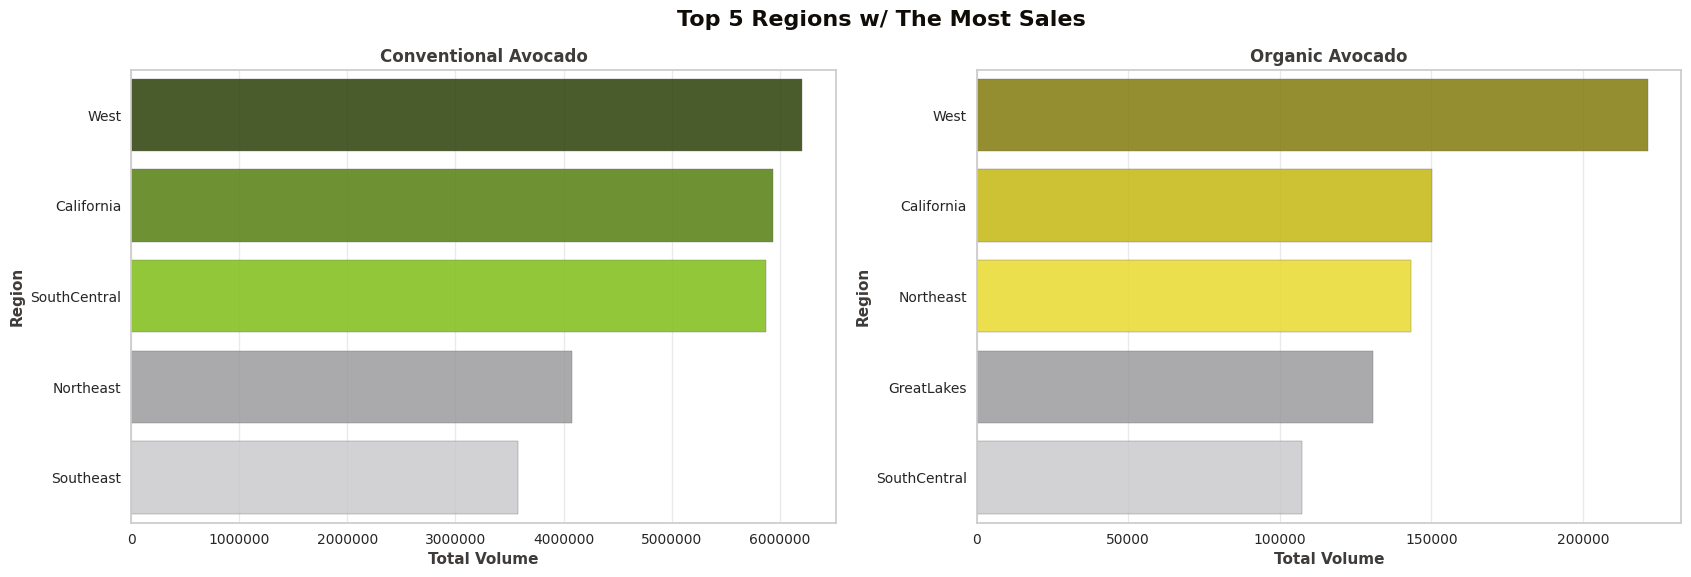

In [ ]:
eda0 = ds.xs(['region', 'Total Volume'], axis = 1)[ds.type == 'conventional']
eda0 = eda0[eda0['region'] != 'TotalUS']
eda0 = eda0.groupby(['region']).aggregate({'Total Volume': np.mean}).sort_values(by = 'Total Volume',
                                                                                 ascending = False).iloc[:5]

eda1 = ds.xs(['region', 'Total Volume'], axis = 1)[ds.type == 'organic']
eda1 = eda1[eda1['region'] != 'TotalUS']
eda1 = eda1.groupby(['region']).aggregate({'Total Volume': np.mean}).sort_values(by = 'Total Volume',
                                                                                 ascending = False).iloc[:5]

fig, ax = plt.subplots(1, 2, figsize = (20, 6))
fig.suptitle('Top 5 Regions w/ The Most Sales', fontweight = 'heavy', fontsize = 16, fontfamily = 'sans-serif',
             color = black_grad[0])

plt.subplot(1, 2, 1)
plt.title('Conventional Avocado', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
bar_left = sns.barplot(x='Total Volume', y = eda0.index, data = eda0, palette = black_grad, edgecolor = black_grad[2],
                       alpha = 0.85)
bar_left.patches[0].set_facecolor(olive_grad[0])
bar_left.patches[1].set_facecolor(olive_grad[1])
bar_left.patches[2].set_facecolor(olive_grad[2])
plt.xlabel('Total Volume', fontweight='bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0)
plt.grid(axis = 'x', alpha = 0.4)
plt.ticklabel_format(style = 'plain', axis = 'x')

plt.subplot(1, 2, 2)
plt.title('Organic Avocado', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
bar_right = sns.barplot(x='Total Volume', y = eda1.index, data = eda1, palette = black_grad, edgecolor = black_grad[2],
                        alpha = 0.85)
bar_right.patches[0].set_facecolor(yellow_grad[1])
bar_right.patches[1].set_facecolor(yellow_grad[2])
bar_right.patches[2].set_facecolor(yellow_grad[3])
plt.xlabel('Total Volume', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0)
plt.grid(axis = 'x', alpha = 0.4)
plt.ticklabel_format(style = 'plain', axis = 'x')
plt.show();

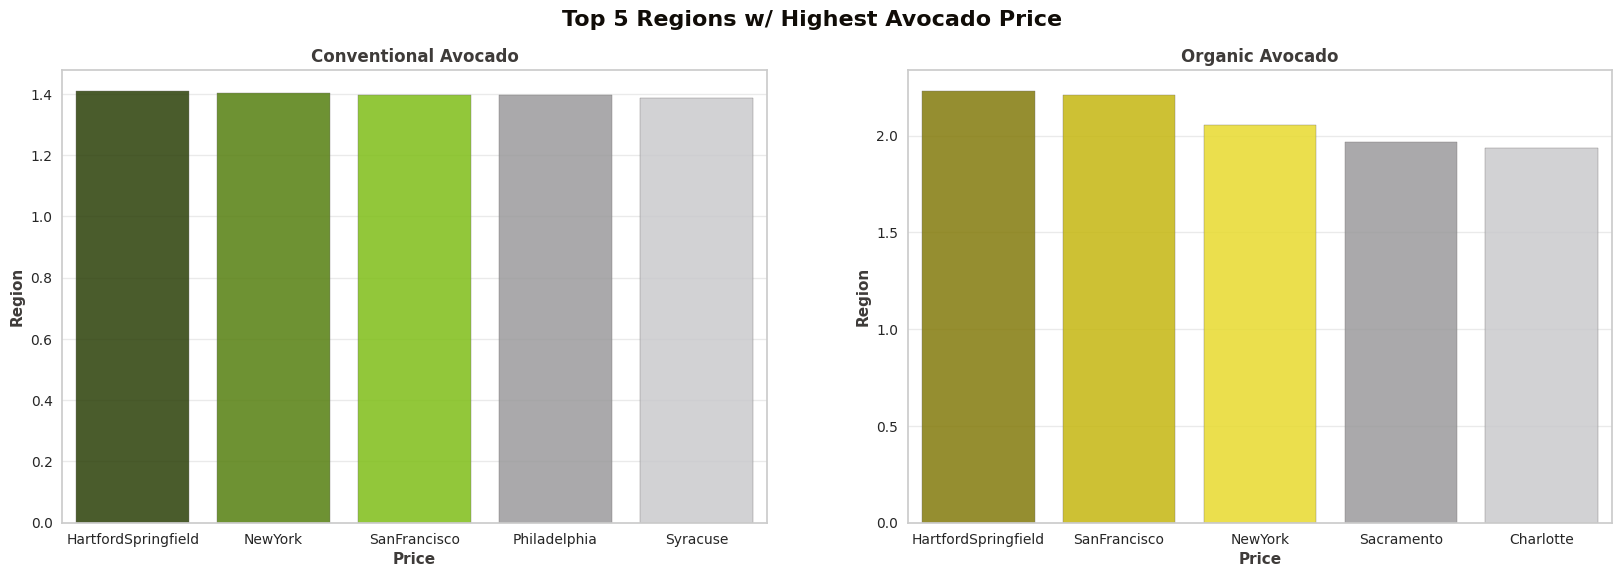

In [ ]:

eda2 = ds.xs(['region', 'AveragePrice'], axis = 1)[ds.type == 'conventional']
eda2 = eda2.groupby(['region']).aggregate({'AveragePrice': np.mean}).sort_values(by = 'AveragePrice',
                                                                                 ascending = False).iloc[:5]

eda3 = ds.xs(['region', 'AveragePrice'], axis = 1)[ds.type == 'organic']
eda3 = eda3.groupby(['region']).aggregate({'AveragePrice': np.mean}).sort_values(by = 'AveragePrice',
                                                                                 ascending = False).iloc[:5]


fig, ax = plt.subplots(1, 2, figsize = (20, 6))
fig.suptitle('Top 5 Regions w/ Highest Avocado Price', fontweight = 'heavy', fontsize = 16, fontfamily = 'sans-serif',
             color = black_grad[0])

plt.subplot(1, 2, 1)
plt.title('Conventional Avocado', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
bar_left = sns.barplot(y = 'AveragePrice', x = eda2.index, data = eda2, palette = black_grad, edgecolor = black_grad[2],
                       alpha = 0.85)
bar_left.patches[0].set_facecolor(olive_grad[0])
bar_left.patches[1].set_facecolor(olive_grad[1])
bar_left.patches[2].set_facecolor(olive_grad[2])
plt.xlabel('Price', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.ticklabel_format(style = 'plain', axis = 'y')


plt.subplot(1, 2, 2)
plt.title('Organic Avocado', fontweight = 'bold', fontsize = '12', fontfamily = 'sans-serif', color = black_grad[1])
bar_right = sns.barplot(y='AveragePrice', x = eda3.index, data = eda3, palette = black_grad, edgecolor = black_grad[2],
                        alpha = 0.85)
bar_right.patches[0].set_facecolor(yellow_grad[1])
bar_right.patches[1].set_facecolor(yellow_grad[2])
bar_right.patches[2].set_facecolor(yellow_grad[3])
plt.xlabel('Price', fontweight='bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.ticklabel_format(style = 'plain', axis = 'y')
plt.show();

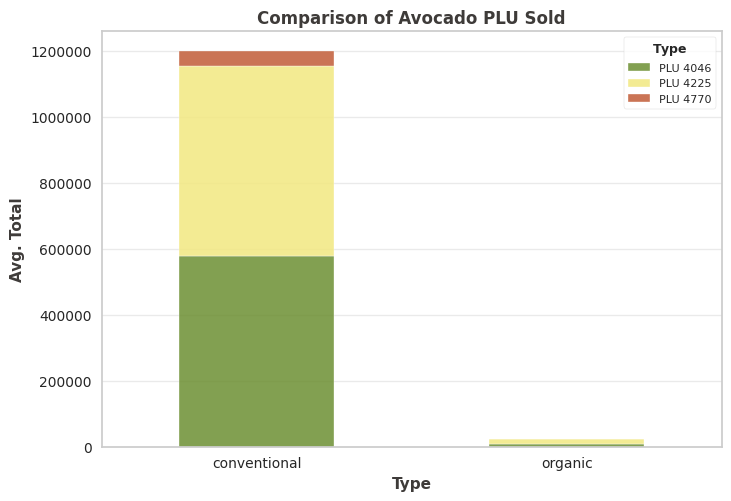

In [ ]:

eda30 = ds.xs(['type', '4046', '4225', '4770'], axis = 1)
eda30 = eda30.groupby(['type']).aggregate({'4046': np.mean, '4225': np.mean, '4770': np.mean})


eda30.plot(kind='bar', stacked = True, color = color_mix[-4:-1], alpha = 0.85)
plt.title('Comparison of Avocado PLU Sold', fontweight = 'bold', fontsize = '12', fontfamily = 'sans-serif',
          color = black_grad[1])
plt.xlabel('Type', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Avg. Total', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.legend(labels = ['PLU 4046','PLU 4225', 'PLU 4770'], title = '$\\bf{Type}$', fontsize = '8', title_fontsize = '9',
           loc = 'upper right', frameon = True)
plt.xticks(rotation = 0)
plt.ticklabel_format(style = 'plain', axis = 'y');

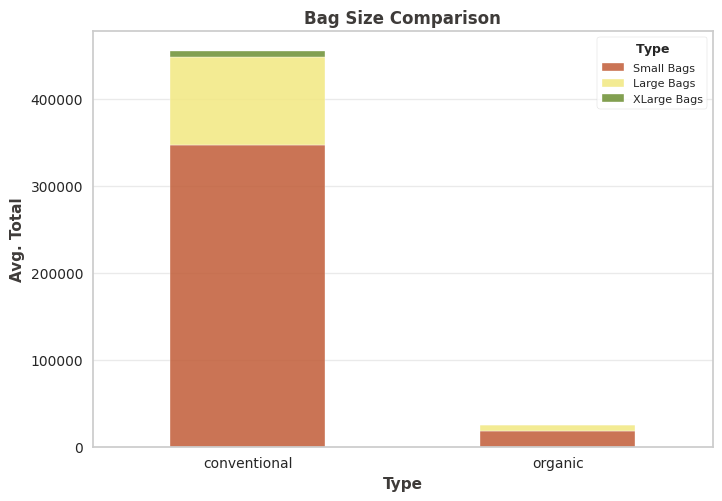

In [ ]:

eda31 = ds.xs(['type', 'Small Bags', 'Large Bags', 'XLarge Bags'], axis = 1)
eda31 = eda31.groupby(['type']).aggregate({'Small Bags': np.mean, 'Large Bags': np.mean, 'XLarge Bags': np.mean})


eda31.plot(kind = 'bar', stacked = True, color = color_mix[3:0:-1], alpha = 0.85)
plt.title('Bag Size Comparison', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
plt.xlabel('Type', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Avg. Total', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.legend(labels = ['Small Bags','Large Bags', 'XLarge Bags'], title = '$\\bf{Type}$', fontsize = 8, title_fontsize = 9,
           loc = 'upper right', frameon = True)
plt.xticks(rotation = 0)
plt.ticklabel_format(style = 'plain', axis = 'y');

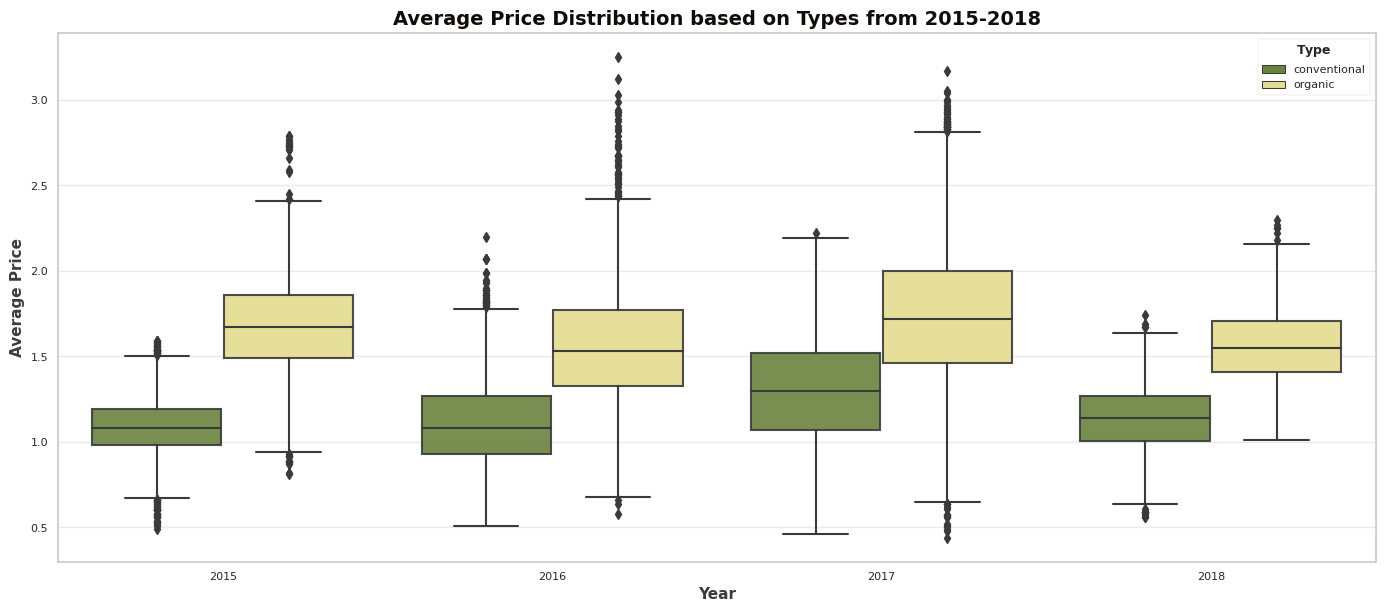

In [ ]:
fig, ax = plt.subplots()
fig.set_size_inches(17, 7)
plt.title('Average Price Distribution based on Types from 2015-2018', fontweight='bold', fontsize = 14,
          fontfamily = 'sans-serif', color = black_grad[0])
sns.boxplot(x = 'year', y = 'AveragePrice', hue = 'type', data = ds, ax = ax, palette = color_mix[1:3],
            boxprops = dict(alpha = 0.9), linewidth = 1.5)
plt.xlabel('Year', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Average Price', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.xticks(fontsize = 8)
plt.yticks(fontsize = 8)
plt.legend(title = '$\\bf{Type}$', fontsize = 8, title_fontsize = 9, loc = 'upper right', frameon = True)
plt.grid(axis = 'y', alpha = 0.4)
plt.show()

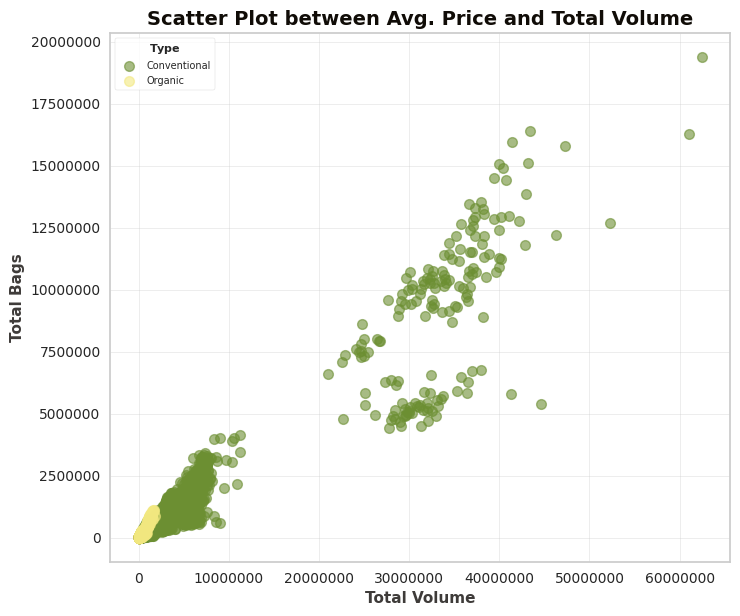

In [ ]:

x0 = ds.xs('Total Volume', axis = 1)[ds.type == 'conventional']
x1 = ds.xs('Total Volume', axis = 1)[ds.type == 'organic']
y0 = ds.xs('Total Bags', axis = 1)[ds.type == 'conventional']
y1 = ds.xs('Total Bags', axis = 1)[ds.type == 'organic']


plt.figure(figsize = (8, 7))
plt.title('Scatter Plot between Avg. Price and Total Volume', fontweight = 'bold', fontsize = 14,
          fontfamily = 'sans-serif', color = black_grad[0])
plt.scatter(x = x0, y = y0, c = color_mix[1], alpha = 0.6, linewidths = 1)
plt.scatter(x = x1, y = y1, c = color_mix[2], alpha = 0.6, linewidths = 1)
plt.legend(['Conventional', 'Organic'], title = '$\\bf{Type}$', fontsize = 7, title_fontsize = 8, loc = 'upper left',
           frameon = True)
plt.xlabel('Total Volume', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Total Bags', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ticklabel_format(style = 'plain', axis = 'both')
plt.grid(axis = 'both', alpha = 0.5, lw = 0.5)
plt.show()

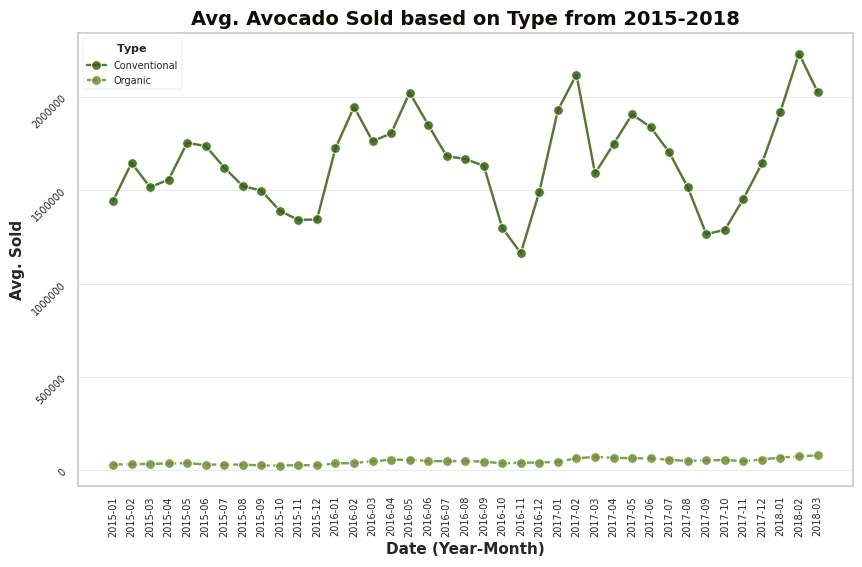

In [ ]:

dseda8 = ds[['Date', 'Total Volume', 'type']]
dseda8['Date'] = pd.DatetimeIndex(dseda8['Date'])
dseda8['Date'] = dseda8['Date'].apply(lambda x: x.strftime('%Y-%m'))
group8 = dseda8.groupby(['Date', 'type'])
mnth_avg8 = group8.aggregate({'Total Volume': np.mean})


plt.figure(figsize = (10, 6))
plt.title('Avg. Avocado Sold based on Type from 2015-2018', fontweight = 'bold', fontsize = 14,
          fontfamily = 'sans-serif', color = black_grad[0])
sns.lineplot(data = mnth_avg8, x = 'Date', y = 'Total Volume', hue = 'type', style = 'type', markers = ['o', 'o'],
             palette = color_mix[0:2], alpha = 0.85)
plt.xlabel('Date (Year-Month)', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ylabel('Avg. Sold', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation = '90', fontsize = 7)
plt.yticks(rotation = '45', fontsize = 7)
plt.grid(axis='y', alpha = 0.5, lw = 0.6)
plt.grid(axis='x', alpha = 0)
plt.legend(labels = ['Conventional', 'Organic'], title = '$\\bf{Type}$', fontsize = 7, title_fontsize = 8, frameon=True);

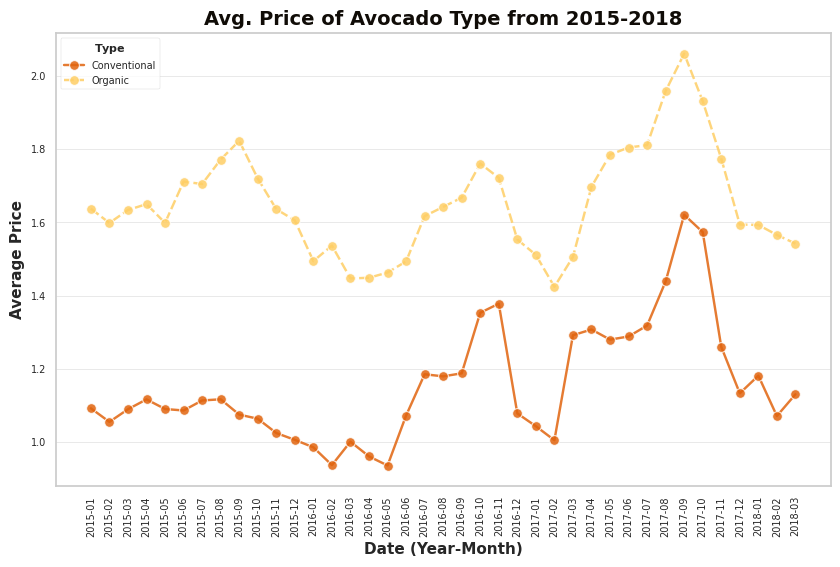

In [ ]:

dseda9 = ds[['Date', 'AveragePrice', 'type']]
dseda9['Date'] = pd.DatetimeIndex(dseda9['Date'])
dseda9['Date'] = dseda9['Date'].apply(lambda x: x.strftime('%Y-%m'))
group9 = dseda9.groupby(['Date', 'type'])
mnth_avg9 = group9.aggregate({'AveragePrice': np.mean})


plt.figure(figsize = (10, 6))
plt.title('Avg. Price of Avocado Type from 2015-2018', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif',
          color = black_grad[0])
sns.lineplot(data = mnth_avg9, x = 'Date', y = 'AveragePrice', hue = 'type', style = 'type', markers = ['o', 'o'],
             palette = 'YlOrBr_r', alpha = 0.85)
plt.xlabel('Date (Year-Month)', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ylabel('Average Price', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ticklabel_format(style = 'plain', axis = 'y')
plt.xticks(rotation = '90', fontsize = 7)
plt.yticks(fontsize = 7)
plt.grid(axis = 'y', alpha = 0.5, lw = 0.6)
plt.grid(axis = 'x', alpha = 0)
plt.legend(labels = ['Conventional', 'Organic'], title = '$\\bf{Type}$', fontsize = 7, title_fontsize = 8,
           loc = 'upper left', frameon = True);

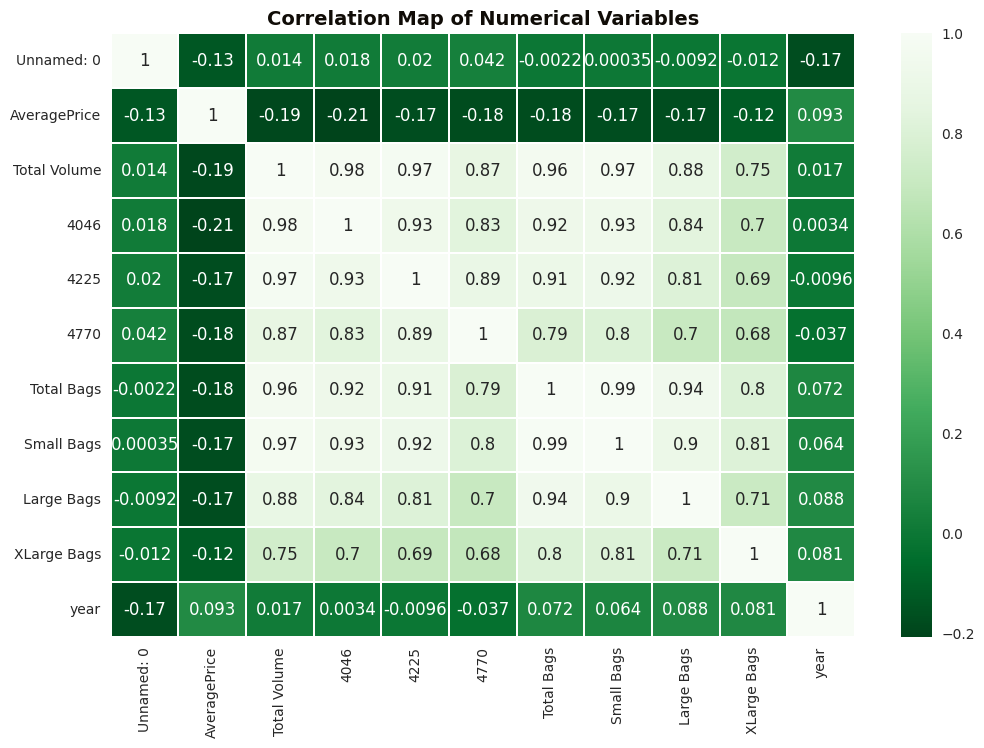

In [ ]:

plt.figure(figsize = (12, 8))
sns.heatmap(ds.corr(), annot = True, cmap = 'Greens_r', linewidths = 0.1)
plt.title('Correlation Map of Numerical Variables', fontsize = 14, fontweight = 'bold', fontfamily = 'sans-serif',
          color = black_grad[0]);

In [ ]:

ds.Date = pd.to_datetime(ds.Date)


ds['month'] = pd.DatetimeIndex(ds['Date']).month

In [ ]:
avc = setup(data = ds, target = 'AveragePrice', train_size = 0.8,
            categorical_features = ['type', 'year', 'region', 'month'], normalize = True, normalize_method = 'robust',
            silent = True, ignore_low_variance = True, session_id = 123)

,Description,Value
0,session_id,123
1,Target,AveragePrice
2,Original Data,"(18249, 15)"
3,Missing Values,False
4,Numeric Features,9
5,Categorical Features,4
6,Ordinal Features,False
7,High Cardinality Features,False
8,High Cardinality Method,None
9,Transformed Train Set,"(14599, 83)"


In [ ]:
models()

,Name,Reference,Turbo
ID,,,
lr,Linear Regression,sklearn.linear_model._base.LinearRegression,True
lasso,Lasso Regression,sklearn.linear_model._coordinate_descent.Lasso,True
ridge,Ridge Regression,sklearn.linear_model._ridge.Ridge,True
en,Elastic Net,sklearn.linear_model._coordinate_descent.Elast...,True
lar,Least Angle Regression,sklearn.linear_model._least_angle.Lars,True
llar,Lasso Least Angle Regression,sklearn.linear_model._least_angle.LassoLars,True
omp,Orthogonal Matching Pursuit,sklearn.linear_model._omp.OrthogonalMatchingPu...,True
br,Bayesian Ridge,sklearn.linear_model._bayes.BayesianRidge,True
ard,Automatic Relevance Determination,sklearn.linear_model._bayes.ARDRegression,False


In [ ]:
test_models = compare_models(sort='R2')

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE,TT (Sec)
et,Extra Trees Regressor,0.0729,0.0116,0.1076,0.9284,0.0432,0.0539,5.7420
catboost,CatBoost Regressor,0.0840,0.0132,0.1146,0.9187,0.0458,0.0615,4.3090
xgboost,Extreme Gradient Boosting,0.0877,0.0147,0.1213,0.9090,0.0484,0.0638,33.1610
rf,Random Forest Regressor,0.0851,0.0150,0.1223,0.9073,0.0492,0.0631,6.2110
lightgbm,Light Gradient Boosting Machine,0.0990,0.0178,0.1332,0.8904,0.0537,0.0732,0.2660
dt,Decision Tree Regressor,0.1169,0.0322,0.1794,0.8010,0.0721,0.0855,0.1230
knn,K Neighbors Regressor,0.1356,0.0353,0.1876,0.7825,0.0768,0.1021,0.6520
gbr,Gradient Boosting Regressor,0.1537,0.0411,0.2025,0.7465,0.0816,0.1155,2.1100
br,Bayesian Ridge,0.1819,0.0582,0.2411,0.6409,0.0974,0.1372,0.0790
ridge,Ridge Regression,0.1819,0.0582,0.2411,0.6409,0.0974,0.1372,0.0320


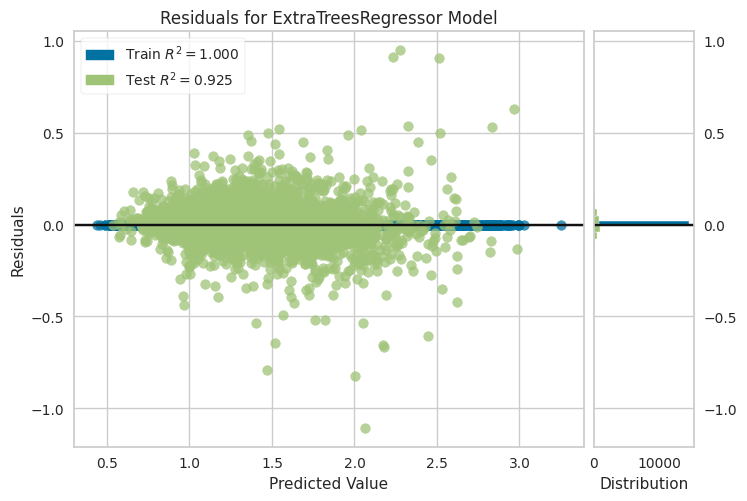

In [ ]:
plot_model(best_models)

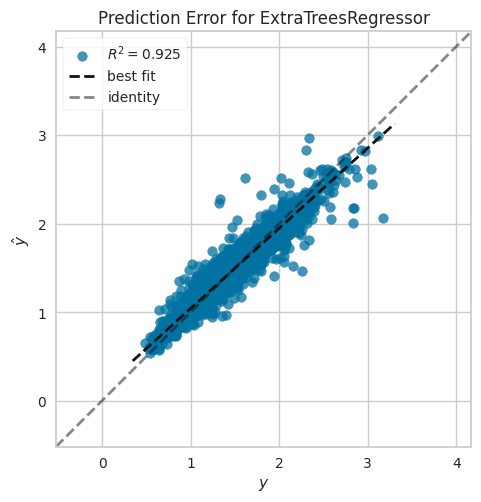

In [ ]:

plot_model(best_models, plot = 'error')

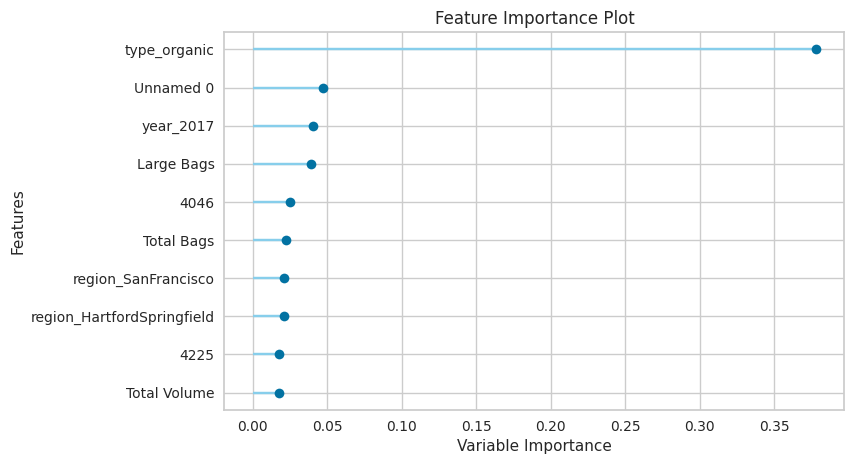

In [ ]:

plot_model(best_models, plot = 'feature')

In [ ]:
tuned_best = tune_model(best_models)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.2114,0.0771,0.2776,0.5397,0.1111,0.1613
1,0.2190,0.0795,0.2819,0.5396,0.1136,0.1669
2,0.2058,0.0687,0.2621,0.5445,0.1095,0.1645
3,0.2095,0.0756,0.2750,0.5403,0.1112,0.1618
4,0.2130,0.0738,0.2716,0.5492,0.1105,0.1645
5,0.2057,0.0702,0.2650,0.5364,0.1096,0.1634
6,0.2146,0.0762,0.2760,0.5246,0.1138,0.1699
7,0.2144,0.0826,0.2874,0.5130,0.1141,0.1612
8,0.2149,0.0776,0.2785,0.5082,0.1144,0.1688


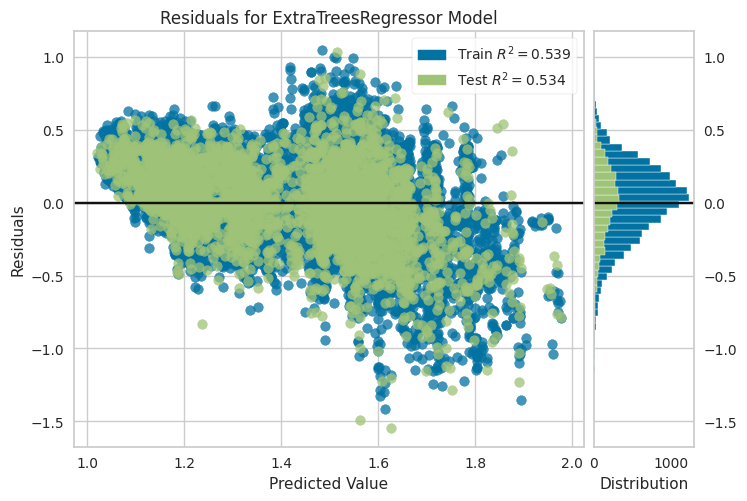

In [ ]:
plot_model(tuned_best)

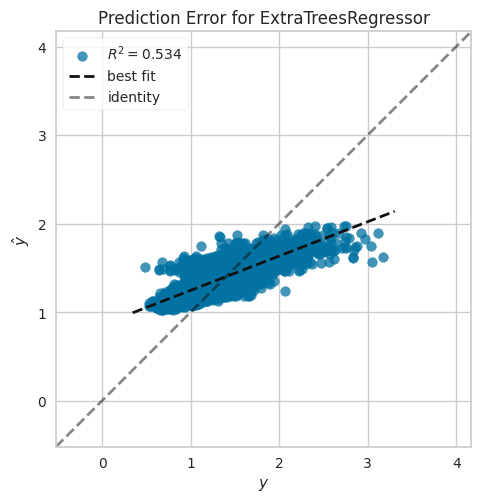

In [ ]:
plot_model(tuned_best, plot = 'error')

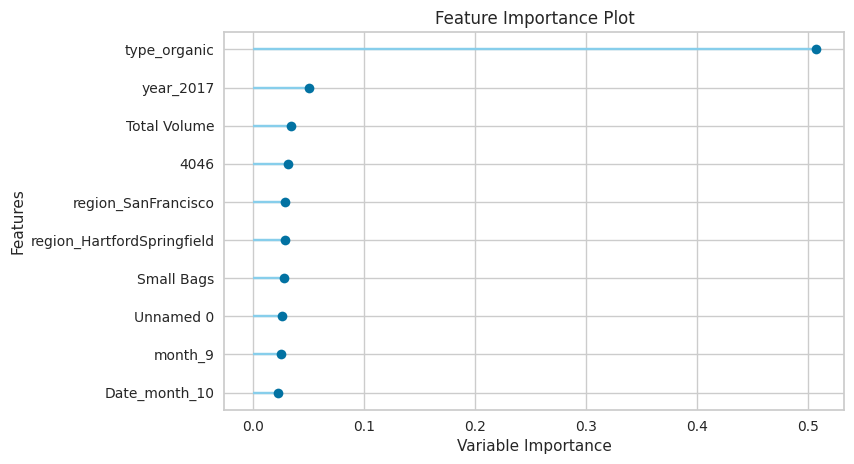

In [ ]:
plot_model(tuned_best, plot = 'feature')

In [ ]:

rf = create_model('rf')

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.0855,0.0153,0.1237,0.9086,0.0488,0.0625
1,0.0866,0.0144,0.1202,0.9164,0.0493,0.0645
2,0.0846,0.0145,0.1202,0.9041,0.0496,0.0638
3,0.0833,0.0145,0.1206,0.9116,0.0483,0.0617
4,0.0797,0.0126,0.1123,0.9230,0.0446,0.0584
5,0.0820,0.0140,0.1184,0.9075,0.0479,0.0611
6,0.0870,0.0164,0.1281,0.8976,0.0512,0.0645
7,0.0872,0.0160,0.1265,0.9057,0.0501,0.0635
8,0.0893,0.0164,0.1280,0.8961,0.0521,0.0669


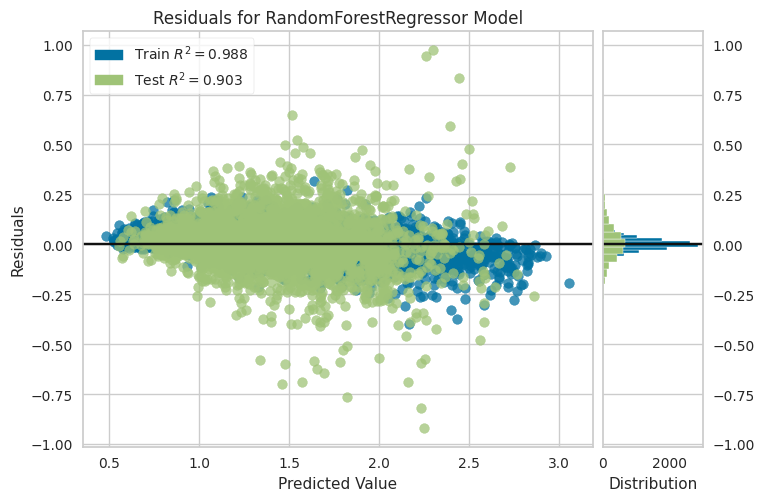

In [ ]:
plot_model(rf)

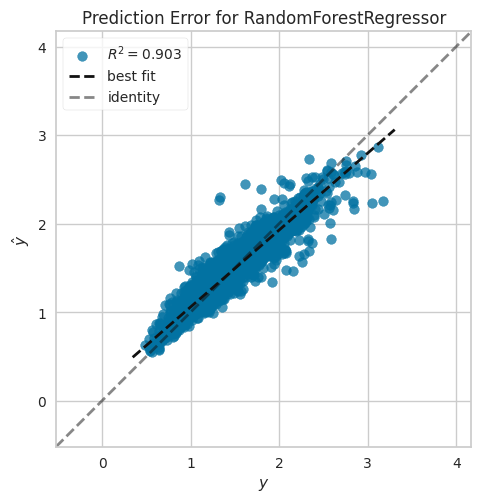

In [ ]:
plot_model(rf, plot = 'error')

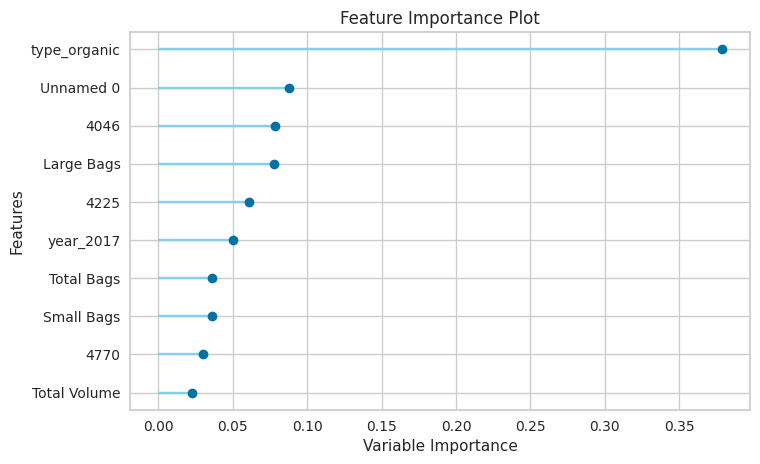

In [ ]:
plot_model(rf, plot = 'feature')

In [ ]:
tune_rf = tune_model(rf)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.1856,0.0597,0.2444,0.6432,0.0974,0.1393
1,0.1928,0.0613,0.2475,0.6451,0.0994,0.1449
2,0.1851,0.0547,0.2338,0.6375,0.0974,0.1450
3,0.1810,0.0557,0.2360,0.6615,0.0953,0.1378
4,0.1875,0.0576,0.2401,0.6480,0.0975,0.1429
5,0.1852,0.0564,0.2375,0.6277,0.0976,0.1435
6,0.1919,0.0613,0.2475,0.6177,0.1014,0.1490
7,0.1919,0.0650,0.2550,0.6167,0.1011,0.1423
8,0.1928,0.0617,0.2485,0.6087,0.1018,0.1490


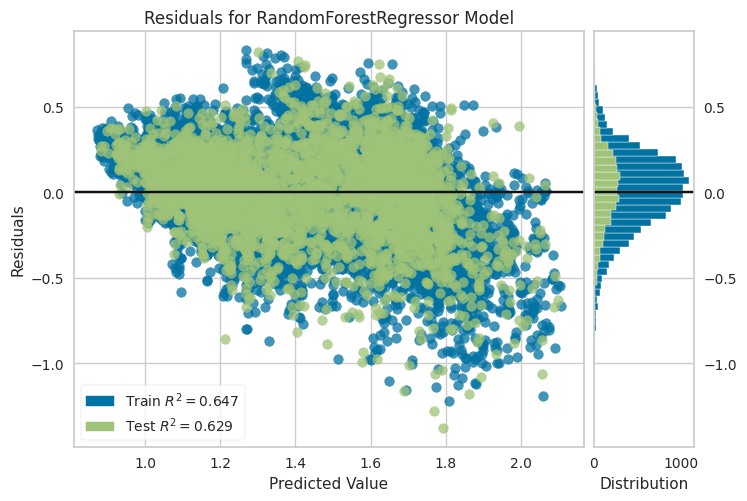

In [ ]:

plot_model(tune_rf)

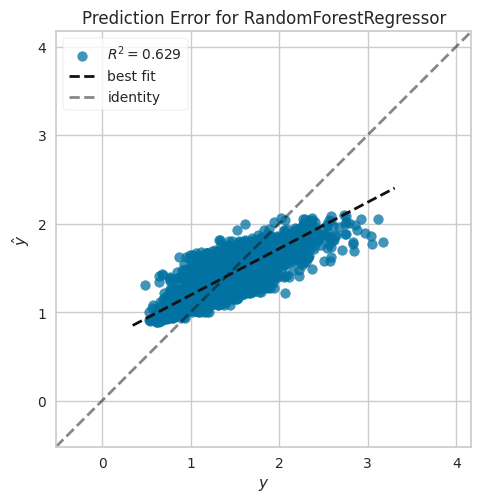

In [ ]:

plot_model(tune_rf, plot = 'error')

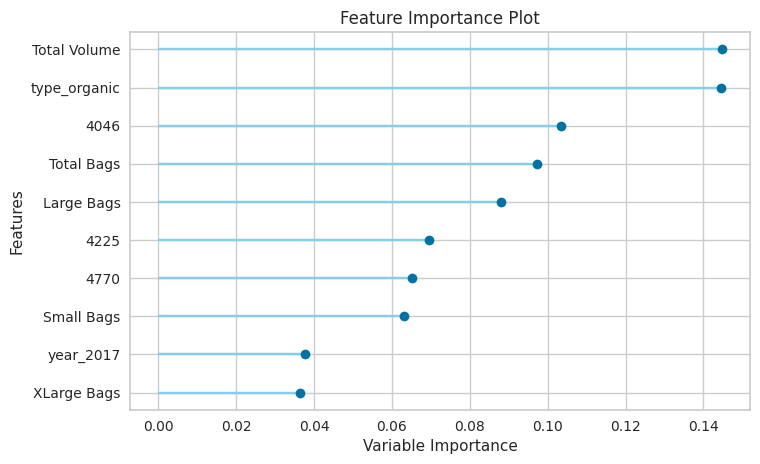

In [ ]:

plot_model(tune_rf, plot = 'feature')

In [ ]:

lgbm = create_model('lightgbm')

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.0989,0.0178,0.1334,0.8936,0.0533,0.0725
1,0.1015,0.0177,0.1332,0.8972,0.0542,0.0750
2,0.0977,0.0164,0.1282,0.8911,0.0530,0.0740
3,0.0953,0.0171,0.1308,0.8961,0.0521,0.0695
4,0.0954,0.0161,0.1271,0.9014,0.0506,0.0698
5,0.0978,0.0173,0.1315,0.8859,0.0532,0.0721
6,0.1014,0.0183,0.1354,0.8856,0.0548,0.0752
7,0.1037,0.0205,0.1431,0.8794,0.0568,0.0753
8,0.0999,0.0181,0.1344,0.8855,0.0548,0.0747


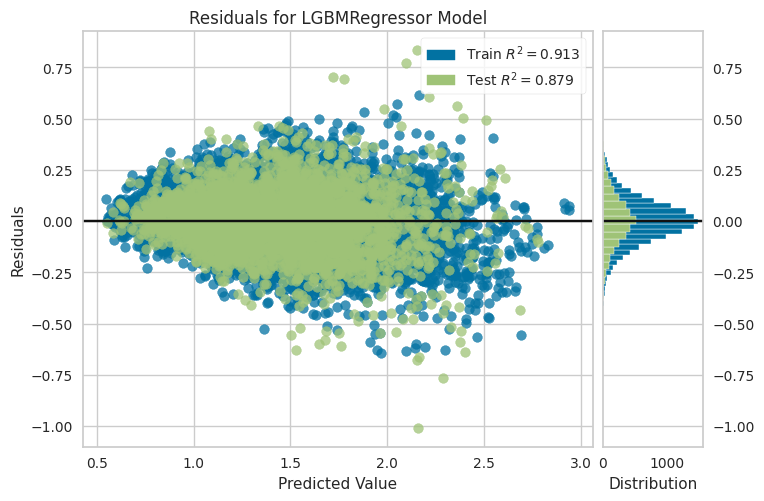

In [ ]:

plot_model(lgbm)

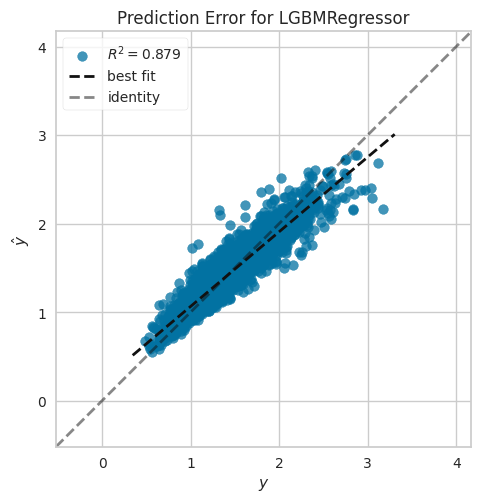

In [ ]:

plot_model(lgbm, plot = 'error')

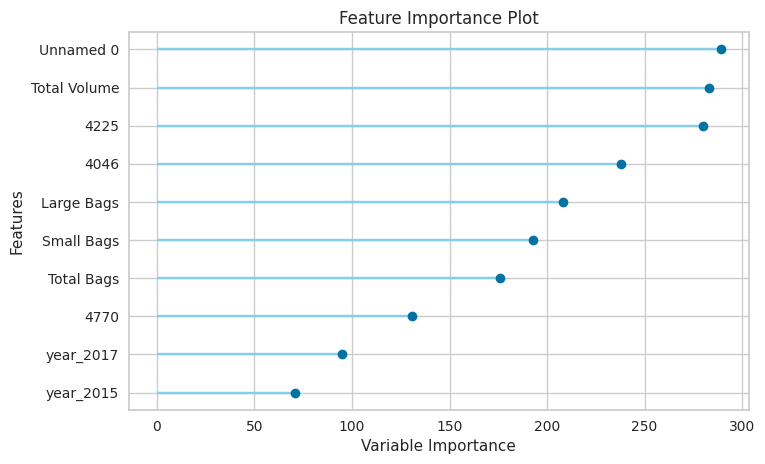

In [ ]:

plot_model(lgbm, plot = 'feature')

In [ ]:
tune_lgbm = tune_model(lgbm)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.1194,0.0264,0.1626,0.8421,0.0644,0.0872
1,0.1309,0.0291,0.1706,0.8315,0.0693,0.0973
2,0.1242,0.0270,0.1645,0.8207,0.0689,0.0962
3,0.1184,0.0265,0.1629,0.8386,0.0650,0.0874
4,0.1205,0.0256,0.1600,0.8435,0.0644,0.0892
5,0.1234,0.0267,0.1635,0.8235,0.0667,0.0924
6,0.1244,0.0266,0.1630,0.8343,0.0673,0.0950
7,0.1298,0.0310,0.1762,0.8171,0.0708,0.0961
8,0.1298,0.0295,0.1717,0.8132,0.0704,0.0981


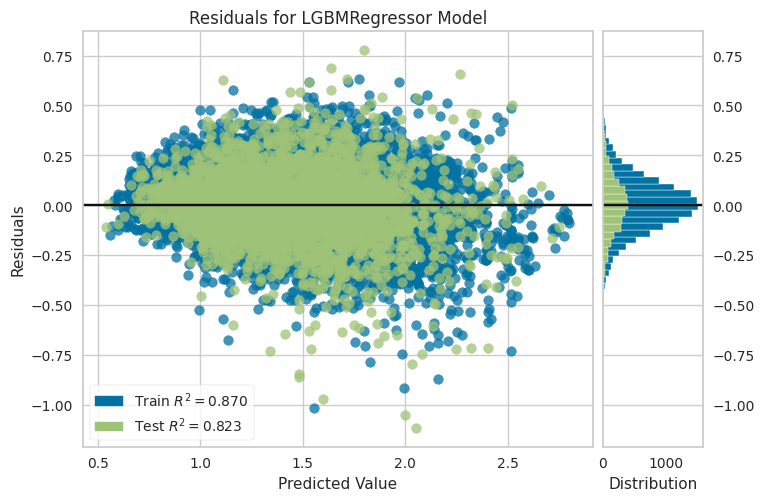

In [ ]:
plot_model(tune_lgbm)

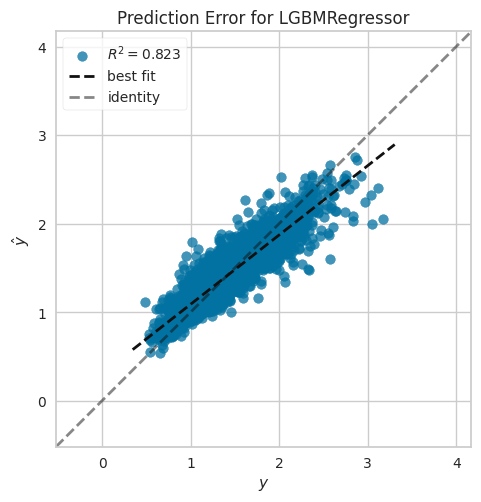

In [ ]:
plot_model(tune_lgbm, plot = 'error')

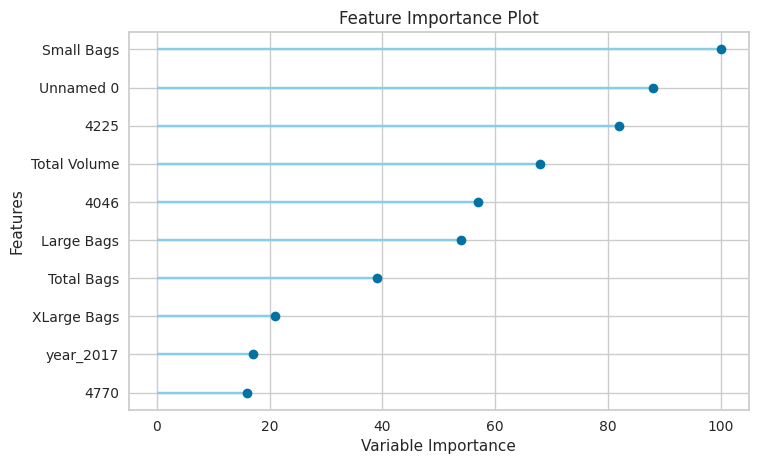

In [ ]:
plot_model(tune_lgbm, plot = 'feature')

In [ ]:
predict_model(best_models)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Extra Trees Regressor,0.0719,0.0122,0.1104,0.9247,0.0437,0.0529


,Unnamed 0,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type_organic,...,Date_month_3,Date_month_5,Date_month_6,Date_month_7,Date_month_8,Date_weekday_6,Date_is_month_end_1,Date_is_month_start_1,AveragePrice,Label
0,0.357143,1.770992,0.749676,1.618697,1.809093,4.169797,5.326726,1.068416,3.828886,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.82,0.8286
1,-0.464286,-0.237191,-0.079796,-0.196736,-0.030364,-0.292676,-0.219610,-0.123732,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.61,1.6229
2,0.321429,0.082122,-0.049090,0.292166,-0.030364,0.257952,0.032864,1.636757,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.68,1.6202
3,0.035714,0.422099,0.783756,0.593626,2.410570,0.183641,0.400364,-0.098366,0.000000,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.01,1.0042
4,0.285714,-0.237167,-0.079152,-0.188752,-0.030364,-0.304423,-0.301527,0.124106,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,1.3729
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3645,0.964286,9.355392,5.424141,14.544580,87.213806,6.352094,5.082823,6.684702,1021.323364,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,0.9354
3646,-0.357143,10.996881,15.420648,14.749743,43.922821,4.805529,6.212162,0.672725,40.000706,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.14,1.1015
3647,0.964286,-0.010962,0.158737,-0.155775,-0.030364,0.301584,0.534609,-0.020226,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.10,1.1046
3648,-0.107143,0.014786,0.053533,-0.007713,-0.030107,0.304855,0.539354,-0.021873,0.000000,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.21,1.2639


In [ ]:
predict_model(rf)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Random Forest Regressor,0.0850,0.0157,0.1253,0.9031,0.0496,0.0624


,Unnamed 0,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type_organic,...,Date_month_3,Date_month_5,Date_month_6,Date_month_7,Date_month_8,Date_weekday_6,Date_is_month_end_1,Date_is_month_start_1,AveragePrice,Label
0,0.357143,1.770992,0.749676,1.618697,1.809093,4.169797,5.326726,1.068416,3.828886,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.82,0.8501
1,-0.464286,-0.237191,-0.079796,-0.196736,-0.030364,-0.292676,-0.219610,-0.123732,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.61,1.6161
2,0.321429,0.082122,-0.049090,0.292166,-0.030364,0.257952,0.032864,1.636757,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.68,1.5550
3,0.035714,0.422099,0.783756,0.593626,2.410570,0.183641,0.400364,-0.098366,0.000000,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.01,1.0397
4,0.285714,-0.237167,-0.079152,-0.188752,-0.030364,-0.304423,-0.301527,0.124106,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,1.2828
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3645,0.964286,9.355392,5.424141,14.544580,87.213806,6.352094,5.082823,6.684702,1021.323364,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,0.9621
3646,-0.357143,10.996881,15.420648,14.749743,43.922821,4.805529,6.212162,0.672725,40.000706,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.14,1.0999
3647,0.964286,-0.010962,0.158737,-0.155775,-0.030364,0.301584,0.534609,-0.020226,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.10,1.1904
3648,-0.107143,0.014786,0.053533,-0.007713,-0.030107,0.304855,0.539354,-0.021873,0.000000,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.21,1.4778


In [ ]:
predict_model(lgbm)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Light Gradient Boosting Machine,0.1024,0.0197,0.1402,0.8786,0.0556,0.0747


,Unnamed 0,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type_organic,...,Date_month_3,Date_month_5,Date_month_6,Date_month_7,Date_month_8,Date_weekday_6,Date_is_month_end_1,Date_is_month_start_1,AveragePrice,Label
0,0.357143,1.770992,0.749676,1.618697,1.809093,4.169797,5.326726,1.068416,3.828886,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.82,0.879362
1,-0.464286,-0.237191,-0.079796,-0.196736,-0.030364,-0.292676,-0.219610,-0.123732,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.61,1.558793
2,0.321429,0.082122,-0.049090,0.292166,-0.030364,0.257952,0.032864,1.636757,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.68,1.471604
3,0.035714,0.422099,0.783756,0.593626,2.410570,0.183641,0.400364,-0.098366,0.000000,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.01,1.052708
4,0.285714,-0.237167,-0.079152,-0.188752,-0.030364,-0.304423,-0.301527,0.124106,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,1.204581
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3645,0.964286,9.355392,5.424141,14.544580,87.213806,6.352094,5.082823,6.684702,1021.323364,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,1.007494
3646,-0.357143,10.996881,15.420648,14.749743,43.922821,4.805529,6.212162,0.672725,40.000706,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.14,1.049828
3647,0.964286,-0.010962,0.158737,-0.155775,-0.030364,0.301584,0.534609,-0.020226,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.10,1.180087
3648,-0.107143,0.014786,0.053533,-0.007713,-0.030107,0.304855,0.539354,-0.021873,0.000000,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.21,1.393180


In [ ]:
final_best = finalize_model(best_models)

plot_model(best_models, plot='parameter')

,Parameters
bootstrap,False
ccp_alpha,0.0
criterion,mse
max_depth,None
max_features,auto
max_leaf_nodes,None
max_samples,None
min_impurity_decrease,0.0
min_impurity_split,None
min_samples_leaf,1


In [ ]:
predict_model(final_best)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Extra Trees Regressor,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000


,Unnamed 0,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type_organic,...,Date_month_3,Date_month_5,Date_month_6,Date_month_7,Date_month_8,Date_weekday_6,Date_is_month_end_1,Date_is_month_start_1,AveragePrice,Label
0,0.357143,1.770992,0.749676,1.618697,1.809093,4.169797,5.326726,1.068416,3.828886,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.82,0.82
1,-0.464286,-0.237191,-0.079796,-0.196736,-0.030364,-0.292676,-0.219610,-0.123732,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.61,1.61
2,0.321429,0.082122,-0.049090,0.292166,-0.030364,0.257952,0.032864,1.636757,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.68,1.68
3,0.035714,0.422099,0.783756,0.593626,2.410570,0.183641,0.400364,-0.098366,0.000000,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.01,1.01
4,0.285714,-0.237167,-0.079152,-0.188752,-0.030364,-0.304423,-0.301527,0.124106,0.000000,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,0.92
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3645,0.964286,9.355392,5.424141,14.544580,87.213806,6.352094,5.082823,6.684702,1021.323364,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.92,0.92
3646,-0.357143,10.996881,15.420648,14.749743,43.922821,4.805529,6.212162,0.672725,40.000706,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.14,1.14
3647,0.964286,-0.010962,0.158737,-0.155775,-0.030364,0.301584,0.534609,-0.020226,0.000000,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.10,1.10
3648,-0.107143,0.014786,0.053533,-0.007713,-0.030107,0.304855,0.539354,-0.021873,0.000000,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.21,1.21


In [ ]:
save_model(final_best,'Final_Best_Model_caesarmario_06May2022')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=None,
          steps=[('dtypes',
                  DataTypes_Auto_infer(categorical_features=['type', 'year',
                                                             'region', 'month'],
                                       display_types=False, features_todrop=[],
                                       id_columns=[], ml_usecase='regression',
                                       numerical_features=[],
                                       target='AveragePrice',
                                       time_features=[])),
                 ('imputer',
                  Simple_Imputer(categorical_strategy='not_available',
                                 fill_value_categorical=None,
                                 fill_v...
                  ExtraTreesRegressor(bootstrap=False, ccp_alpha=0.0,
                                      criterion='mse', max_depth=None,
                                      max_features='auto', max_leaf_nodes=None,
                       